# 03 — Checkpoint Evaluation, 97-Task `GIFT-Eval` Benchmark, Paired Bootstrap CIs & Forecast Gallery

**Goal:** Reproduce the complete `GIFT-Eval` progressive evaluation story offline-first from `checkpoints/run*/model_soup.safetensors` and `results/*.csv`, verify `step_20000` vs. `5`-snapshot soup selection on the held-out `1,500`-series validation set, inspect disaggregated slices and pre-origin blackout stress tests, and plot multi-quantile forecasts alongside candid failure modes.

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore", category=FutureWarning)

REPO_ROOT = Path.cwd() if (Path.cwd() / "src" / "tsfm_proto").exists() else Path.cwd().parent
_ENV_GE_SRC = os.environ.get("GIFT_EVAL_SRC", "")
GIFT_EVAL_SRC = Path(_ENV_GE_SRC) if _ENV_GE_SRC else None
_ENV_GE_DATA = os.environ.get("GIFT_EVAL")
GIFT_EVAL_DATA = Path(_ENV_GE_DATA) if _ENV_GE_DATA else (REPO_ROOT / "data" / "GiftEval")
for p in (REPO_ROOT / "src", GIFT_EVAL_SRC):
    if p is not None and str(p) and p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tsfm_proto import TSFMModel
from tsfm_proto.config import TSFMConfig
from tsfm_proto.data import SubsetDatasetStore
from tsfm_proto.eval_metrics import EvalEntry, predict_entries

HF_REPO_ID = os.environ.get("TSFM_HF_REPO_ID") or None


def _load_model_or_init(run_name: str) -> tuple[TSFMModel, TSFMConfig, bool]:
    """Load local/HF checkpoint cleanly, falling back to config-matched init on a bare clone without weights."""
    try:
        model, cfg = TSFMModel.from_pretrained(
            run_name,
            checkpoints_root=REPO_ROOT / "checkpoints",
            hf_repo_id=HF_REPO_ID,
            device=DEVICE,
        )
        return model, cfg, False
    except FileNotFoundError:
        cfg = TSFMConfig.from_yaml(REPO_ROOT / "configs" / f"{run_name}.yaml")
        model = TSFMModel(cfg).to(device=DEVICE, dtype=torch.float32).eval()
        return model, cfg, True

plt.rcParams.update(
    {
        "figure.dpi": 115,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Evaluation notebook initialized on device={DEVICE}")

Evaluation notebook initialized on device=mps


## 1. Offline-First `TSFMModel.from_pretrained(...)` & Internal Validation Check (`step_20000` vs. Soup)

Both `step_20000.safetensors` and the unweighted `5`-snapshot `float64` WSD cooldown average (`steps 16k..20k` saved at `model_soup.safetensors`) are audited on the `1,500`-series (`66`-dataset) internal holdout *before* running the `97`-task `GIFT-Eval` benchmark. Because WSD cosine decay spans the final `25%` (`5k` steps: `15k -> 20k`), the earliest snapshot (`step_16000`, `20%` into cooldown) still sits near the peak LR (`2.73e-4` vs. `1.50e-5` at `step_20000`)—yielding a `3–3` validation split in `val_soup_vs_last.csv` (`5`-snap soup wins on `Runs 2, 3, 4`; `step_20000` edges ahead on `Runs 0, 1, 5`), while all `6` `model_soup.safetensors` checkpoints are evaluated uniformly on `GIFT-Eval` per pre-registered protocol.

In [2]:
model_r5, cfg_r5, r5_untrained = _load_model_or_init("run5_coupled_synth_mix")
print(
    f"Loaded `{cfg_r5.run_name}` via `TSFMModel.from_pretrained` ({'bare-clone config fallback' if r5_untrained else 'trained soup'}): "
    f"{model_r5.count_parameters():,} params, c_in={cfg_r5.c_in}, head={cfg_r5.head_type}, group_attn={cfg_r5.use_group_attn}"
)

val_cmp = pd.read_csv(REPO_ROOT / "results" / "val_soup_vs_last.csv")
print("\nInternal 1,500-Series Validation: step_20000 vs 5-Snapshot float64 Soup:")
print(
    val_cmp[
        [
            "run_name",
            "n_params",
            "steady_ms_per_step",
            "last_val_nmwql",
            "soup_val_nmwql",
            "last_val_nmase",
            "soup_val_nmase",
            "soup_val_cov80",
        ]
    ].to_string(index=False)
)

Loaded `run5_coupled_synth_mix` via `TSFMModel.from_pretrained` (trained soup): 16,317,344 params, c_in=17, head=median_probit, group_attn=True

Internal 1,500-Series Validation: step_20000 vs 5-Snapshot float64 Soup:
                    run_name  n_params  steady_ms_per_step  last_val_nmwql  soup_val_nmwql  last_val_nmase  soup_val_nmase  soup_val_cov80
            run0_v0_baseline  14816800              208.64        0.566439        0.569612        0.694360        0.695827        0.754589
          run1_data_balanced  14816800              209.85        0.516116        0.520025        0.628948        0.633225        0.764294
 run2_missingness_suffix_cpm  14816800              214.45        0.536348        0.533334        0.651914        0.643432        0.766280
 run3_probit_localscale_lags  15136288              220.64        0.529235        0.527693        0.647850        0.643792        0.759574
run4_multivariate_group_attn  16317344              248.57        0.531440        0.530

## 2. Official 97-Task `GIFT-Eval` Progression & Paired Bootstrap 95% CIs

Key findings across the `6` progressive iterations (`Runs 0..5`, geometric mean across `97` tasks normalized per task by official `Seasonal_Naive`, `B = 10,000` paired bootstrap resamples at `seed = 42`):
- **Data & Loss Balancing (`Run 0 -> Run 1`, `0` param delta):** `nMWQL` drops `-3.11%` (task CI `[0.948, 0.988]`, 28-family cluster CI `[0.937, 0.991]`, `68.0%` task win rate); `Healthcare` drops `-23.6%` (`0.8749 -> 0.6686`) and `Econ/Fin` drops `-12.6%` (`0.9682 -> 0.8463`).
- **Missingness + Horizon<=1024 + Blackout (`Run 1 -> Run 2`, `0` param delta):** Cuts `20`-step and `64`-step pre-origin blackout `nMWQL` by `-18.6%` and `-19.7%`, and improves `Horizon > 512` (`0.6500 -> 0.6354`, `Cov80: 0.664 -> 0.755`), while costing `+0.42%` overall clean `nMWQL` / `+1.32%` `nMASE` due to `30%` blackout + longer single-pass horizons.
- **Probit + `W=64` Local Scale + Modular Lags (`Run 2 -> Run 3`):** Recovers `nMASE` (`0.8778 -> 0.8713`), boosts `Horizon <= 512 nMASE` (`0.8339 -> 0.8224`), lowers `64`-step blackout error (`0.8265 -> 0.8237`), and improves the **`91` non-`10S` tasks by `-1.30%`** (`0.5740 -> 0.5665`); the `6` zero-shot `10S` tasks experience a `+29.8%` variance spike (`1.344 -> 1.745`) that masks this gain in the `97`-task average.
- **`GroupAttention` + `15%` Coupled Synthetic Priors (`Run 4 -> Run 5`):** Real `GiftEvalPretrain` contains `past_feat_dynamic_real` in only `13 / 93` subset directories (`8.5%` of series, `91.0%` concentrated in 3 cloud VM dirs), further gated by `0.35` group-packing probability; adding coupled synthetic drivers unlocks `GroupAttention` cleanly—cutting `Past Covariates` by **`-7.98%`** (`0.7052 -> 0.6489`), `Web/CloudOps` by **`-9.24%`** (`0.7850 -> 0.7125`), and reaching **`#1` on every overall metric** (`0.5946` raw / `0.5907` `+Clamp/Snap` / `0.5890` `+SymAvg+Clamp`, `-4.37%` raw / `-5.27%` post-processed vs. `Run 0`).

In [3]:
ablation = pd.read_csv(REPO_ROOT / "results" / "gifteval_ablation_summary.csv")
cis = pd.read_csv(REPO_ROOT / "results" / "gifteval_bootstrap_cis.csv")

print("97-Task GIFT-Eval Progression:")
print(ablation.to_string(index=False))

print("\nPaired Bootstrap 95% CIs (B=10,000, seed=42; 97 Tasks & 28 Dataset Families):")
print(cis.to_string(index=False))

97-Task GIFT-Eval Progression:
                    run_name      postproc  n_params  n_tasks  geo_nmwql  geo_nmase  mean_cov80
            run0_v0_baseline           raw  14816800       97   0.621814   0.890478    0.767725
            run0_v0_baseline    clamp_snap  14816800       97   0.618752   0.887276    0.772207
          run1_data_balanced           raw  14816800       97   0.602506   0.866374    0.760862
          run1_data_balanced    clamp_snap  14816800       97   0.599215   0.863516    0.765362
 run2_missingness_suffix_cpm           raw  14816800       97   0.605029   0.877849    0.791124
 run2_missingness_suffix_cpm    clamp_snap  14816800       97   0.601798   0.875455    0.795512
 run3_probit_localscale_lags           raw  15136288       97   0.607354   0.871302    0.773134
 run3_probit_localscale_lags    clamp_snap  15136288       97   0.603837   0.867949    0.778299
run4_multivariate_group_attn           raw  16317344       97   0.604711   0.867795    0.774887
run4_mult

### 2b. Official 97-Task `GIFT-Eval` Leaderboard Context (`results/gifteval_leaderboard_comparison.csv`)

Contextualizing a `16.32M`-param scratch prototype (`~8.9h` final pipeline compute: `39.3m` subset + `~7.76h` [`7.70h` TB span] 6-run training + `~30m` 6-soup eval; `~10.4h` total wall-clock incl. early diagnostics) on one laptop (`Apple M2 Max`) against `141` complete official `GIFT-Eval` models shows `Run 5 (+SymAvg+Clamp)` earning **insertion rank `#106` against the `141` official baselines** (`105` ahead, `36` beaten: statistically significant paired gains at `p < 0.05` on both 97-task and 28-family cluster CIs over `Chronos_large #119`, `Moirai_small #120`, `Chronos_base #121`, `TimesFM #124`, and `Seasonal_Naive #136`; aggregate point-estimate leads / statistical ties alongside `Moirai_large #107`, `TFT #109`, `Moirai_base #111`, `iTransformer #114`, and `PatchTST #104`), while illuminating the capacity/context gap to frontier zero-shot baselines (`Chronos-2 #61`, `TimesFM-2.5 #69`, `t0-gamma #11`, `t0-beta #42`, `t0-alpha #72`).

In [4]:
lb = pd.read_csv(REPO_ROOT / "results" / "gifteval_leaderboard_comparison.csv")
print("Official 97-Task GIFT-Eval Leaderboard Context (Top Baselines, Ranks Around Run 5, and Seasonal_Naive):")
keep_mask = (
    lb["table_rank"].isin(set(range(1, 7)) | set(range(13, 27)))
    | lb["model"].astype(str).str.contains("Seasonal_Naive|run0_v0_baseline", regex=True)
    | (lb["table_rank"] >= len(lb) - 1)
)
sub_lb = lb[keep_mask].sort_values("table_rank").reset_index(drop=True)
cols = [
    "table_rank",
    "model",
    "category",
    "geo_nmwql",
    "geo_nmwql_excl_10s",
    "geo_nmase",
    "wins_vs_sn_nmwql",
    "wins_vs_sn_nmase",
    "official_rank_of_141",
]
rows_fmt = []
prev_r = None
for _, row in sub_lb[cols].iterrows():
    cur_r = int(row["table_rank"])
    if prev_r is not None and cur_r - prev_r > 1:
        rows_fmt.append({c: "..." for c in cols})
    rows_fmt.append({c: row[c] for c in cols})
    prev_r = cur_r
print(pd.DataFrame(rows_fmt).to_string(index=False))

Official 97-Task GIFT-Eval Leaderboard Context (Top Baselines, Ranks Around Run 5, and Seasonal_Naive):
table_rank                                        model                              category geo_nmwql geo_nmwql_excl_10s geo_nmase wins_vs_sn_nmwql wins_vs_sn_nmase official_rank_of_141
         1                                     t0-gamma                 Pretrained TSFM (TFC)  0.451973           0.450188  0.660842               96               95                   11
         2                                      t0-beta                 Pretrained TSFM (TFC)  0.473751           0.469733  0.686539               97               95                   42
         3                                     Timer-S1                       Pretrained TSFM  0.485299           0.479263   0.69335               95               94                   60
         4                                    Chronos-2                Pretrained TSFM (120M)  0.485416           0.483584  0.697793            

## 3. Disaggregated Slices & Pre-Origin Blackout Stress Tests

Below we inspect domain/horizon/covariate slices (`gifteval_slices_summary.csv`) alongside the `90`-task pre-origin blackout stress test (`gifteval_blackout_stress.csv`). Notice why `0`-step clean blackout `geo_nmwql` prints `0.6661` on `90` tasks rather than `0.5946` on all `97`: `scripts/eval_gifteval.py` filters `do_blackout` via `(med_ctx >= 96.0) & (frequency not in {"A", "Y", "Q"})` so a `64`-step blackout fits (excluding `7` ultra-short/annual/quarterly tasks), subsamples `<= 256` evenly spaced windows/task (`np.linspace`), and normalizes against deterministic zero-spread **Point `Seasonal_Naive`** (`_build_seasonal_naive_deciles`, whose `MWQL` denominator is `~0.864x` smaller on the `<= 256`-window `90`-task benchmark [`0.872x` on full `90`-task windows] than `statsforecast`'s Gaussian-interval `Seasonal_Naive` in `seasonal_naive_official_reference.csv`, inflating normalized `nMWQL` accordingly while point `nMASE` stays close at `0.8573` vs. `0.8592` on `90`-task full windows [`0.8596` across all `97`]).

In [5]:
slices = pd.read_csv(REPO_ROOT / "results" / "gifteval_slices_summary.csv")
raw_slices = slices[slices["postproc"] == "raw"]
piv_mwql = raw_slices.pivot(index="slice", columns="run_name", values="geo_nmwql")
key_rows = [
    "Overall (97)",
    "Domain: Healthcare",
    "Domain: Econ/Fin",
    "Domain: Web/CloudOps",
    "Past Covariates",
    "Multivariate",
    "Horizon > 512",
    "Missing-Flagged Datasets",
    "Low-Res Freq (A/Q/M/W)",
    "High-Res Freq (D/H/Min/S)",
]
print("Disaggregated Raw Geometric-Mean nMWQL Across Progressive Iterations:")
print(piv_mwql.loc[key_rows].round(4).to_string())

blk = pd.read_csv(REPO_ROOT / "results" / "gifteval_blackout_stress.csv")
piv_blk = blk.pivot(index="blackout_steps", columns="run_name", values="geo_nmwql")
print("\n90-Task Pre-Origin Blackout Stress Test (geo_nmwql):")
print(piv_blk.round(4).to_string())

Disaggregated Raw Geometric-Mean nMWQL Across Progressive Iterations:
run_name                   run0_v0_baseline  run1_data_balanced  run2_missingness_suffix_cpm  run3_probit_localscale_lags  run4_multivariate_group_attn  run5_coupled_synth_mix
slice                                                                                                                                                                          
Overall (97)                         0.6218              0.6025                       0.6050                       0.6074                        0.6047                  0.5946
Domain: Healthcare                   0.8749              0.6686                       0.6995                       0.7299                        0.6609                  0.6567
Domain: Econ/Fin                     0.9682              0.8463                       0.8850                       0.8799                        0.8602                  0.8437
Domain: Web/CloudOps                 0.7579       

## 4. Live Multi-Quantile Forecast Gallery (`q10..q90` & `q50`)

Below we run **live inference** with our saved soup checkpoints on two complementary regimes:
1. **Pre-Origin Blackout Resilience (`Run 1` vs. `Run 2`):** Blanking the final `64` historical steps (`2` full `P=32` patches, matching `fig5` and `gifteval_blackout_stress.csv`) before forecast origin `T_origin` on a real periodic hourly series breaks zero-filled baselines while `Run 2` bridges the blackout cleanly via observed-only scaling and blank-key masking.
2. **Covariate-Coupled Ops (`Run 4` vs. `Run 5`, Clamped Deciles):** On real `bizitobs_l2c/H/short` (`Past Covariates`), `Run 5` sharpens point trajectories and `[q10, q90]` / `[q20, q80]` uncertainty bands relative to `Run 4`.

bizitobs_l2c/H/short (win #0, var #5) MAE (Clamp): Run 4=5.9010 -> Run 5=2.9815 (-49.5%)


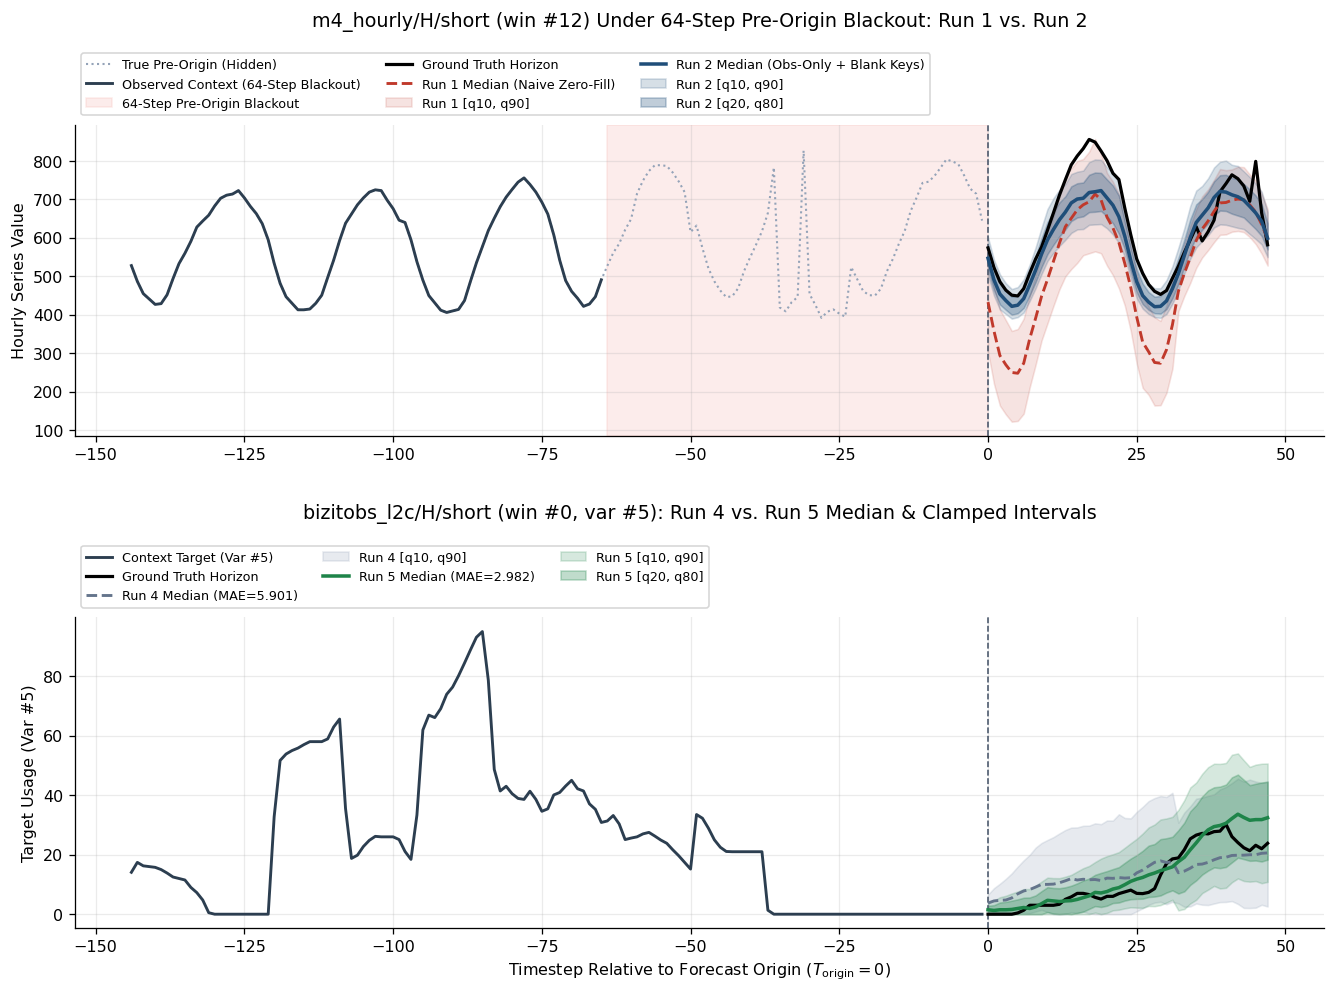

In [6]:
def _load_demo_series() -> tuple[EvalEntry, EvalEntry, str, str]:
    if GIFT_EVAL_DATA.exists():
        os.environ["GIFT_EVAL"] = str(GIFT_EVAL_DATA)
        from gluonts.time_feature import get_seasonality
        from gift_eval.data import Dataset

        from tsfm_proto.data import normalize_pandas_freq

        ds_hr = Dataset(name="m4_hourly", term="short", to_univariate=False)
        inp_h, lbl_h = list(zip(ds_hr.test_data.input, ds_hr.test_data.label))[12]
        tgt_h = np.asarray(inp_h["target"], dtype=np.float32)
        if tgt_h.ndim == 1:
            tgt_h = tgt_h[None, :]
        fut_h = np.asarray(lbl_h["target"], dtype=np.float32)
        if fut_h.ndim == 1:
            fut_h = fut_h[None, :]
        ent_blackout = EvalEntry(
            target=tgt_h,
            past_cov=None,
            prediction_length=int(ds_hr.prediction_length),
            future_target=fut_h,
            season_length=int(get_seasonality(normalize_pandas_freq(ds_hr.freq))),
        )

        ds_biz = Dataset(name="bizitobs_l2c/H", term="short", to_univariate=False)
        inp_b, lbl_b = list(zip(ds_biz.test_data.input, ds_biz.test_data.label))[0]
        tgt_b = np.asarray(inp_b["target"], dtype=np.float32)
        if tgt_b.ndim == 1:
            tgt_b = tgt_b[None, :]
        fut_b = np.asarray(lbl_b["target"], dtype=np.float32)
        if fut_b.ndim == 1:
            fut_b = fut_b[None, :]
        cov_b = inp_b.get("past_feat_dynamic_real")
        cov_b = np.asarray(cov_b, dtype=np.float32) if cov_b is not None else None
        if cov_b is not None and cov_b.ndim == 1:
            cov_b = cov_b[None, :]
        ent_cov = EvalEntry(
            target=tgt_b,
            past_cov=cov_b,
            prediction_length=int(ds_biz.prediction_length),
            future_target=fut_b,
            season_length=int(get_seasonality(normalize_pandas_freq(ds_biz.freq))),
        )
        return ent_blackout, ent_cov, "m4_hourly/H/short (win #12)", "bizitobs_l2c/H/short (win #0, var #5)"

    # Portable fallback if running on a remote clone without GIFT_EVAL mounted.
    sub_dir = REPO_ROOT / "data" / "gifteval_pretrain_subset"
    if sub_dir.exists() and any(sub_dir.glob("*/part-00000.parquet")):
        store = SubsetDatasetStore(sub_dir, val_num_series=1500)
        vals = store.build_validation_examples(max_examples=20)
        ex0 = vals[0]
        e0 = EvalEntry(ex0.context_target, None, ex0.horizon, ex0.label_target, 24)
        return e0, e0, f"val:{ex0.dataset_name}", f"val:{ex0.dataset_name}"

    t_all = np.arange(304, dtype=np.float32)
    cov_s = np.stack(
        [np.sin(2.0 * np.pi * t_all / 24.0), np.cos(2.0 * np.pi * t_all / 12.0)],
        axis=0,
    ).astype(np.float32)
    tgt_s = np.stack(
        [10.0 + (1.0 + 0.1 * k) * cov_s[0] + 0.5 * cov_s[1] for k in range(6)],
        axis=0,
    ).astype(np.float32)
    e_blk = EvalEntry(tgt_s[:1, :256], None, 48, tgt_s[:1, 256:], 24)
    e_cov = EvalEntry(tgt_s[:, :256], cov_s[:, :256], 48, tgt_s[:, 256:], 24)
    return e_blk, e_cov, "synthetic_demo/H/short (bare-clone fallback)", "synthetic_demo_cov/H/short (var #5)"


ent_blk, ent_cov, title_blk, title_cov = _load_demo_series()
m_r1, c_r1, _ = _load_model_or_init("run1_data_balanced")
m_r2, c_r2, _ = _load_model_or_init("run2_missingness_suffix_cpm")
m_r4, c_r4, _ = _load_model_or_init("run4_multivariate_group_attn")

p_r1_blk = predict_entries(m_r1, c_r1, [ent_blk], DEVICE, batch_size=1, apply_blackout_steps=64).clamp_deciles[0]
p_r2_blk = predict_entries(m_r2, c_r2, [ent_blk], DEVICE, batch_size=1, apply_blackout_steps=64).clamp_deciles[0]
p_r4_cov = predict_entries(m_r4, c_r4, [ent_cov], DEVICE, batch_size=1).clamp_deciles[0]
p_r5_cov = predict_entries(model_r5, cfg_r5, [ent_cov], DEVICE, batch_size=1).clamp_deciles[0]

v_idx = 5 if ent_cov.target.shape[0] > 5 else 0
mae_r4 = float(np.mean(np.abs(p_r4_cov[4, :, v_idx] - ent_cov.future_target[v_idx])))
mae_r5 = float(np.mean(np.abs(p_r5_cov[4, :, v_idx] - ent_cov.future_target[v_idx])))
print(f"{title_cov} MAE (Clamp): Run 4={mae_r4:.4f} -> Run 5={mae_r5:.4f} ({100.0 * (mae_r5 - mae_r4) / max(mae_r4, 1e-8):+.1f}%)")

fig, axes = plt.subplots(2, 1, figsize=(11.5, 8.8), constrained_layout=True)

# Top panel: 64-step blackout resilience (Run 1 vs Run 2).
ctx_show = min(144, int(ent_blk.target.shape[1]))
blk_len = min(64, ctx_show)
y_ctx = ent_blk.target[0, -ctx_show:].copy()
y_ctx_masked = y_ctx.copy()
y_ctx_masked[-blk_len:] = np.nan
y_fut = ent_blk.future_target[0]
h1 = len(y_fut)
t_ctx = np.arange(-ctx_show, 0)
t_fut = np.arange(0, h1)

axes[0].plot(t_ctx, y_ctx, color="#94A3B8", lw=1.3, ls=":", label="True Pre-Origin (Hidden)")
axes[0].plot(t_ctx, y_ctx_masked, color="#2c3e50", lw=1.8, label="Observed Context (64-Step Blackout)")
axes[0].axvspan(-64, 0, color="#f5b7b1", alpha=0.25, label="64-Step Pre-Origin Blackout")
axes[0].axvline(0, color="#475569", lw=1.0, ls="--")
axes[0].plot(t_fut, y_fut, color="black", lw=2.0, label="Ground Truth Horizon")
axes[0].plot(t_fut, p_r1_blk[4, :, 0], color="#c0392b", lw=1.8, ls="--", label="Run 1 Median (Naive Zero-Fill)")
axes[0].fill_between(t_fut, p_r1_blk[0, :, 0], p_r1_blk[8, :, 0], color="#c0392b", alpha=0.14, label="Run 1 [q10, q90]")
axes[0].plot(t_fut, p_r2_blk[4, :, 0], color="#1f4e79", lw=2.2, label="Run 2 Median (Obs-Only + Blank Keys)")
axes[0].fill_between(t_fut, p_r2_blk[0, :, 0], p_r2_blk[8, :, 0], color="#1f4e79", alpha=0.18, label="Run 2 [q10, q90]")
axes[0].fill_between(t_fut, p_r2_blk[1, :, 0], p_r2_blk[7, :, 0], color="#1f4e79", alpha=0.28, label="Run 2 [q20, q80]")
axes[0].set_ylabel("Hourly Series Value")
axes[0].set_title(f"{title_blk} Under 64-Step Pre-Origin Blackout: Run 1 vs. Run 2", pad=62)
axes[0].legend(ncol=3, fontsize=8.0, loc="lower left", bbox_to_anchor=(0.0, 1.01), frameon=True)

# Bottom panel: Run 4 vs Run 5 on covariate-informed series (var #5), comparing both interval bands.
ctx_c = ent_cov.target[v_idx, -144:]
fut_c = ent_cov.future_target[v_idx]
h2 = len(fut_c)
axes[1].plot(np.arange(-len(ctx_c), 0), ctx_c, color="#2c3e50", lw=1.8, label=f"Context Target (Var #{v_idx})")
axes[1].axvline(0, color="#475569", lw=1.0, ls="--")
axes[1].plot(np.arange(0, h2), fut_c, color="black", lw=2.0, label="Ground Truth Horizon")
axes[1].plot(np.arange(0, h2), p_r4_cov[4, :, v_idx], color="#64748B", lw=1.8, ls="--", label=f"Run 4 Median (MAE={mae_r4:.3f})")
axes[1].fill_between(np.arange(0, h2), p_r4_cov[0, :, v_idx], p_r4_cov[8, :, v_idx], color="#94A3B8", alpha=0.22, label="Run 4 [q10, q90]")
axes[1].plot(np.arange(0, h2), p_r5_cov[4, :, v_idx], color="#1e8449", lw=2.2, label=f"Run 5 Median (MAE={mae_r5:.3f})")
axes[1].fill_between(np.arange(0, h2), p_r5_cov[0, :, v_idx], p_r5_cov[8, :, v_idx], color="#1e8449", alpha=0.18, label="Run 5 [q10, q90]")
axes[1].fill_between(np.arange(0, h2), p_r5_cov[1, :, v_idx], p_r5_cov[7, :, v_idx], color="#1e8449", alpha=0.28, label="Run 5 [q20, q80]")
axes[1].set_ylabel(f"Target Usage (Var #{v_idx})")
axes[1].set_title(f"{title_cov}: Run 4 vs. Run 5 Median & Clamped Intervals", pad=62)
axes[1].set_xlabel(r"Timestep Relative to Forecast Origin ($T_{\mathrm{origin}} = 0$)")
axes[1].legend(ncol=3, fontsize=8.0, loc="lower left", bbox_to_anchor=(0.0, 1.01), frameon=True)
fig.get_layout_engine().set(h_pad=0.18)
plt.show()

## 5. Candid Failure-Mode Audit (`7 / 97` Tasks Above `1.0` `nMWQL` in `Run 5`)

`Run 5` beats `Seasonal_Naive` on **`90 / 97` (`92.8%`)** tasks on `nMWQL` (`77 / 97` raw, **`82 / 97` `+SymAvg+Clamp`** on `nMASE`), reaching **`0.5637` raw / `0.5581` `+SymAvg+Clamp`** outside `10S`. Inspecting the exact `7` tasks above `1.0` highlights our clearest bottlenecks and motivates [`docs/04_with_more_time_roadmap.md`](../docs/04_with_more_time_roadmap.md):
- **`bizitobs_application/10S/{medium,long}` & `bizitobs_service/10S/{medium,long}`:** `GiftEvalPretrain` (`878.26 GB`, `152` dirs) contains **zero (`0 / 152`)** `10S` dirs (and our leakage guard strictly forbids fine-tuning on `GIFT-Eval` test sets). In `bizitobs_application/10S/long`, the full raw series has `8,834` steps (`24.54h`), leaving `7,934` steps (`22.04h < 24h`) before `H=900` (`2.50h`), which our `128`-patch window caps at `99` context patches (`3,168` steps = `8.80h`). Meanwhile `season_length = 360` (`60` min, raw-unit `7,934`-step `win0` lag-360 Pearson `autocorr = 0.9959` on ch0 / `0.9782` on ch1, mean `0.9870`) spans `360 / 32 = 11.25` patches (`8`-step intra-patch phase drift per hour), `SEASONAL_LAGS` stops at `S = 96 < 360`, and single-pass `29`-patch readout damps sharp bursts (`Cov80 = 0.290`). *Addressed by Pillar 1 (`3:1` interleaved `Kalman-KDA` recurrence + pointwise-gated full attention), Pillar 3 (`4x8` sub-patch stem), and Pillar 7 (`TSMixup` + GARCH bursts + frequency-adaptive `S in {144, 360, 720, 1440}` + synthetic `10S` telemetry).*
- **`bizitobs_l2c/5T/long` (`H=720`, `2.5` days):** Long `23`-patch single-pass horizon with phase shift against `P=32` patches and `<1.7` weekly cycles in `4,096` steps (*addressed by Pillar 1 `3:1` `Kalman-KDA` memory + Pillar 3 `4x8` sub-patch stem*).
- **`m4_daily/D/short` (`1.208` `nMWQL`):** Random-walk financial levels where naive persistence dominates zero-shot cross-domain quantile priors (*addressed by Pillar 4 origin-blended readout frame $\mu^{\text{dec}}_{v,T}$*).
- **`us_births/M/short` (`1.052` `nMWQL`, down from `1.501` in `Run 0`):** Monthly calendar seasonality across coarse `P=32` patches with short context (*solved by Pillar 2 known calendar covariates $\mathbf{z}$ + Pillar 3 fine-grained `4x8` sub-patch stem*).

Tasks beating Seasonal Naive (nMWQL < 1.0): Raw=90/97, +SymAvg+Clamp=90/97
Tasks beating Seasonal Naive (nMASE < 1.0): Raw=77/97, +SymAvg+Clamp=82/97

Exact 7 Residual Tasks with Run 5 Raw nMWQL > 1.0:
                        dataset frequency  horizon  is_mv  has_past_cov    nmwql    nmase    cov80
  bizitobs_application/10S/long       10S      900   True          True 1.847448 2.118049 0.290000
bizitobs_application/10S/medium       10S      600   True          True 1.802585 2.290400 0.402083
      bizitobs_service/10S/long       10S      900   True          True 1.625171 2.545250 0.711217
    bizitobs_service/10S/medium       10S      600   True          True 1.487395 2.535339 0.722579
               m4_daily/D/short         D       14  False         False 1.208363 1.344132 0.746595
              us_births/M/short         M       12  False         False 1.052345 1.054219 0.916667
           bizitobs_l2c/5T/long        5T      720   True          True 1.050476 0.963628 0.542937


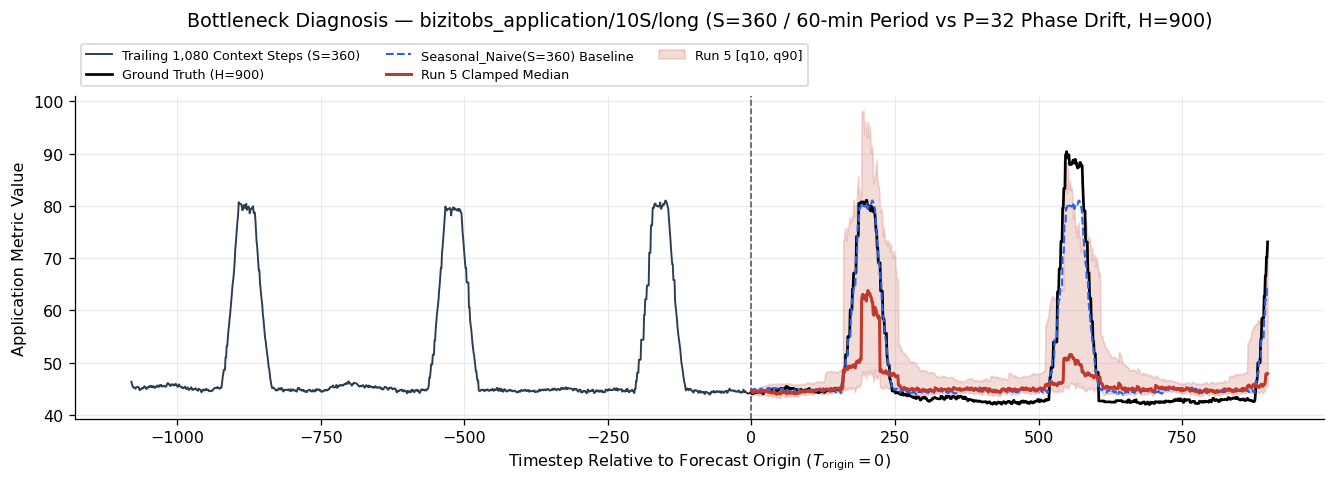

In [7]:
r5_tasks = pd.read_csv(REPO_ROOT / "results" / "gifteval_per_task_run5_coupled_synth_mix.csv")
r5_raw = r5_tasks[r5_tasks["postproc"] == "raw"]
r5_sym = r5_tasks[r5_tasks["postproc"] == "sym_avg_clamp"]
print(f"Tasks beating Seasonal Naive (nMWQL < 1.0): Raw={(r5_raw['nmwql'] < 1.0).sum()}/97, +SymAvg+Clamp={(r5_sym['nmwql'] < 1.0).sum()}/97")
print(f"Tasks beating Seasonal Naive (nMASE < 1.0): Raw={(r5_raw['nmase'] < 1.0).sum()}/97, +SymAvg+Clamp={(r5_sym['nmase'] < 1.0).sum()}/97")
print("\nExact 7 Residual Tasks with Run 5 Raw nMWQL > 1.0:")
print(
    r5_raw[r5_raw["nmwql"] > 1.0]
    .sort_values("nmwql", ascending=False)[
        ["dataset", "frequency", "horizon", "is_mv", "has_past_cov", "nmwql", "nmase", "cov80"]
    ]
    .to_string(index=False)
)

# Failure-mode diagnostic plot on bizitobs_application/10S/long (3 full S=360 cycles of 60-min context [-1080..0] + H=900 [0..900] with Seasonal_Naive overlay).
def _load_failure_demo() -> tuple[EvalEntry, str]:
    if GIFT_EVAL_DATA.exists():
        os.environ["GIFT_EVAL"] = str(GIFT_EVAL_DATA)
        from gluonts.time_feature import get_seasonality
        from gift_eval.data import Dataset
        from tsfm_proto.data import normalize_pandas_freq

        ds_f = Dataset(name="bizitobs_application", term="long", to_univariate=False)
        inp_f, lbl_f = list(zip(ds_f.test_data.input, ds_f.test_data.label))[0]
        tgt_f = np.asarray(inp_f["target"], dtype=np.float32)
        if tgt_f.ndim == 1:
            tgt_f = tgt_f[None, :]
        fut_f = np.asarray(lbl_f["target"], dtype=np.float32)
        if fut_f.ndim == 1:
            fut_f = fut_f[None, :]
        cov_f = inp_f.get("past_feat_dynamic_real")
        cov_f = np.asarray(cov_f, dtype=np.float32) if cov_f is not None else None
        if cov_f is not None and cov_f.ndim == 1:
            cov_f = cov_f[None, :]
        return (
            EvalEntry(tgt_f, cov_f, int(ds_f.prediction_length), fut_f, int(get_seasonality(normalize_pandas_freq(ds_f.freq)))),
            "bizitobs_application/10S/long (S=360 / 60-min Period vs P=32 Phase Drift, H=900)",
        )
    return ent_cov, f"fallback:{title_cov}"


ent_fail, title_fail = _load_failure_demo()
p_r5_fail = predict_entries(model_r5, cfg_r5, [ent_fail], DEVICE, batch_size=1).clamp_deciles[0]
fig_f, ax_f = plt.subplots(figsize=(11.5, 4.1), constrained_layout=True)
ctx_show_f = min(ent_fail.target.shape[1], 1080)
ctx_f = ent_fail.target[0, -ctx_show_f:]
fut_f = ent_fail.future_target[0]
s_len = max(1, ent_fail.season_length)
last_season = ent_fail.target[0, -s_len:]
sn_pred = np.resize(last_season, len(fut_f))

ax_f.axvline(0, color="#475569", lw=1.0, ls="--")
ax_f.plot(np.arange(-len(ctx_f), 0), ctx_f, color="#2c3e50", lw=1.2, label=f"Trailing {len(ctx_f):,} Context Steps (S={s_len})")
ax_f.plot(np.arange(0, len(fut_f)), fut_f, color="black", lw=1.7, label=f"Ground Truth (H={len(fut_f)})")
ax_f.plot(np.arange(0, len(fut_f)), sn_pred, color="#2563EB", lw=1.3, ls="--", label=f"Seasonal_Naive(S={s_len}) Baseline")
ax_f.plot(np.arange(0, len(fut_f)), p_r5_fail[4, :, 0], color="#c0392b", lw=1.9, label="Run 5 Clamped Median")
ax_f.fill_between(np.arange(0, len(fut_f)), p_r5_fail[0, :, 0], p_r5_fail[8, :, 0], color="#c0392b", alpha=0.18, label="Run 5 [q10, q90]")
ax_f.set_ylabel("Application Metric Value")
ax_f.set_title(f"Bottleneck Diagnosis — {title_fail}", pad=44)
ax_f.set_xlabel(r"Timestep Relative to Forecast Origin ($T_{\mathrm{origin}} = 0$)")
ax_f.legend(ncol=3, fontsize=8.0, loc="lower left", bbox_to_anchor=(0.0, 1.01), frameon=True)
plt.show()

## Summary
- Across the `6` progressive `~16M`-param models trained on `~2.8%` of the corpus series (`0.31%` of corpus bytes, `2.74 GB` subset, `~7.76h` [`7.70h` TB span] training / `~8.9h` final pipeline compute, `~10.4h` total wall-clock incl. early diagnostics), `Run 5` reduces overall `97`-task `GIFT-Eval` `nMWQL` from `0.6218` to **`0.5946` raw / `0.5890` `+SymAvg+Clamp`**, beating `Seasonal_Naive` on **`90 / 97` (`92.8%`)** tasks (`82 / 97` on `nMASE`) and reaching **`0.5581` (`0.5637` raw)** outside the zero-pretrain `10S` cadence.
- The hardest controlled gains come from dataset/task-loss balancing (`Run 0 -> 1`, `-3.11%` overall, `68.0%` win rate), missingness + blackout regularization (`Run 1 -> 2`, `-19.7%` on `64`-step blackouts), Probit + local scale + seasonal lags (`Run 2 -> 3`, `-1.30%` excluding `10S`), and coupling `GroupAttention` with synthetic causal drivers (`Run 4 -> 5`, `-7.98%` on `Past Covariates`).
- All remaining gaps—in particular `10S` sub-hourly periodicity (`S=360`) and long-horizon sharp bursts—point directly to the scaling roadmap in [`docs/04_with_more_time_roadmap.md`](../docs/04_with_more_time_roadmap.md).